# 🏠 Prédiction du Prix des Maisons (Boston Housing)
**Auteur**: ANYOUZOA NDOUNA Gabriel Ange

**Jeu de données :** `BostonHousing.csv` (506 lignes, 14 colonnes)

---

## 1. Introduction & Objectifs du Projet

Ce projet vise à construire un modèle d'apprentissage supervisé (*Supervised Learning*) de type **Régression Linéaire** pour prédire la valeur médiane des maisons (`medv`) à partir de caractéristiques urbaines et structurelles.

### 🎯 Étapes de la démarche :
1. **Exploration & Nettoyage des Données (EDA) :** Inspection, contrôle qualité, vérification des types et des doublons.
2. **Analyse Exploratoire Visuelle :** Distributions et corrélations entre variables avec Matplotlib & Seaborn.
3. **Modélisation par Machine Learning (Scikit-Learn) :** Découpage `train_test_split`, entraînement du modèle `LinearRegression` et évaluation via $R^2$.
4. **Publication du projet :** Export et mise en valeur sur GitHub avec `README.md`.

## 2. Étape 1 : Exploration Initiale & Nettoyage des Données (EDA)

Dans cette première étape, nous préparons l'environnement de travail et effectuons les vérifications initiales du jeu de données :
1. **Importation des bibliothèques :** Chargement des outils nécessaires pour la manipulation de données (`pandas`, `numpy`), la visualisation (`matplotlib`, `seaborn`) et l'apprentissage automatique (`scikit-learn`).
2. **Chargement du dataset :** Lecture du fichier `house_prices.csv` déposé dans l'environnement Google Colab.
3. **Inspection initiale :** Vérification des dimensions du tableau (nombre de lignes et de colonnes) et affichage des premiers enregistrements.

1. **Importation des bibliothèques :**

In [1]:
# 1. Importation des bibliothèques essentielles
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Activation de l'affichage des graphiques intégrés dans Colab
%matplotlib inline

# 2. Chargement du dataset house_prices.csv
df = pd.read_csv("housing.csv")


* dimension de notre Dataset (nombre de lignes et colonnes) :

In [2]:
#dimension du Dataset (nombre de lignes et de colonnes)
df.shape

(489, 4)

### 2.1 Inspection de la Structure & Contrôle Qualité

Nous effectuons une série de vérifications pas à pas pour contrôler la qualité des données :
1. **Aperçu des données (`head`)**
2. **Types de colonnes & mémoire (`info`)**
3. **Détection des valeurs manquantes (`isnull`)**
4. **Détection des doublons (`duplicated`)**
5. **Statistiques descriptives (`describe`)**

* Aperçu des données (`head`) :

In [3]:
# Affichage des 5 premières lignes
df.head()

,RM,LSTAT,PTRATIO,MEDV
0,6.575,4.98,15.3,504000.0
1,6.421,9.14,17.8,453600.0
2,7.185,4.03,17.8,728700.0
3,6.998,2.94,18.7,701400.0
4,7.147,5.33,18.7,760200.0


* Types de colonnes & mémoire (`info`):

In [4]:
# Informations sur les types de données et valeurs non nulles
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 489 entries, 0 to 488
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   RM       489 non-null    float64
 1   LSTAT    489 non-null    float64
 2   PTRATIO  489 non-null    float64
 3   MEDV     489 non-null    float64
dtypes: float64(4)
memory usage: 15.4 KB


* Détection des valeurs manquantes (`isnull`):

In [5]:
# Somme des valeurs manquantes par colonne
df.isnull().sum()

,0
RM,0
LSTAT,0
PTRATIO,0
MEDV,0


* Détection des doublons (`duplicated`):

In [6]:
# Détection des doublons
df.duplicated().sum()

np.int64(0)

* Statistiques descriptives (`describe`):

In [8]:
# Statistiques descriptives
df.describe()

,RM,LSTAT,PTRATIO,MEDV
count,489.000000,489.000000,489.000000,4.890000e+02
mean,6.240288,12.939632,18.516564,4.543429e+05
std,0.643650,7.081990,2.111268,1.653403e+05
min,3.561000,1.980000,12.600000,1.050000e+05
25%,5.880000,7.370000,17.400000,3.507000e+05
50%,6.185000,11.690000,19.100000,4.389000e+05
75%,6.575000,17.120000,20.200000,5.187000e+05
max,8.398000,37.970000,22.000000,1.024800e+06


## 3. Étape 2 : Analyse Exploratoire Visuelle (EDA)

Dans cette étape, nous étudions visuellement la distribution de notre variable cible (`medv`) ainsi que ses relations et corrélations avec les autres variables du dataset :
1. **Histogramme de la cible (`medv`) :** Observer la distribution des prix des maisons.
2. **Carte de chaleur (`Heatmap`) :** Identifier les variables explicatives ayant la plus forte corrélation avec le prix.
3. **Nuage de points (`Scatter Plot`) :** Visualiser la relation entre la variable la plus corrélée (ex: nombre moyen de pièces `rm`) et le prix (`medv`).



### 3.1 Distribution de la variable cible (`medv`)

Nous traçons un histogramme pour observer la répartition des valeurs médianes des maisons (`medv`). Cela nous permet de vérifier la forme de la distribution (symétrie, étalement et présence d'éventuelles valeurs extrêmes).

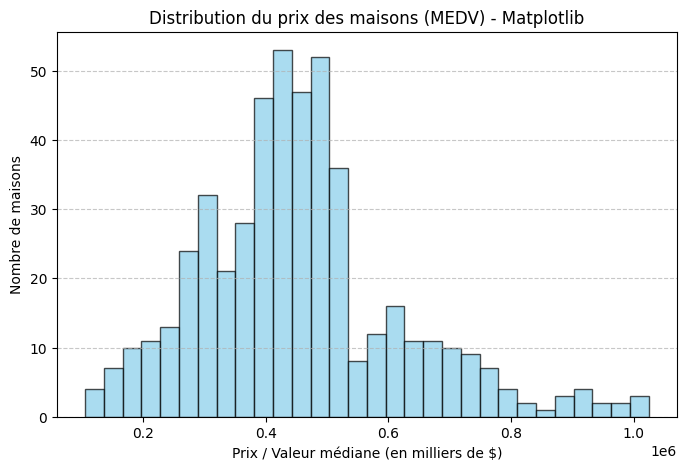

In [9]:
# 1. Histogramme avec Matplotlib pur
plt.figure(figsize=(8, 5))
plt.hist(df['MEDV'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Distribution du prix des maisons (MEDV) - Matplotlib')
plt.xlabel('Prix / Valeur médiane (en milliers de $)')
plt.ylabel('Nombre de maisons')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

---

### 3.2 Carte de chaleur des corrélations (*Heatmap*)

Nous calculons la matrice de corrélation linéaire entre toutes les variables numériques du jeu de données et nous la visualisons avec `plt.imshow()`. Cela nous permet d'identifier quelles variables explicatives ont une forte corrélation (positive ou négative) avec la cible `medv`.

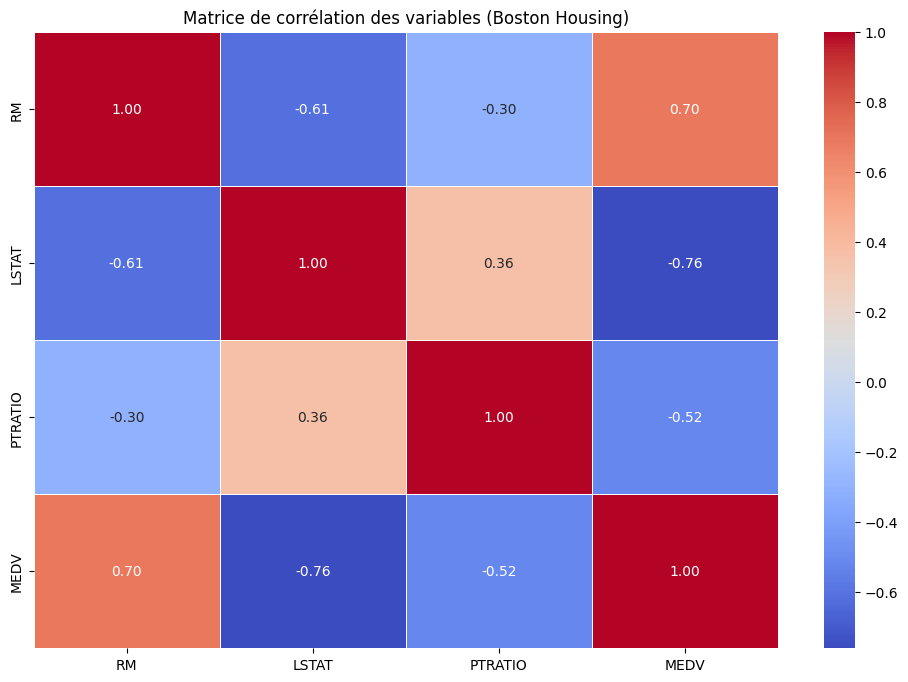

In [10]:
# 2. Carte de chaleur des corrélations entre les variables
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Matrice de corrélation des variables (Boston Housing)')
plt.show()

---

### 3.3 Relation entre le nombre de pièces (`rm`) et le prix (`medv`)

D'après la matrice de corrélation, le nombre moyen de pièces par logement (`rm`) présente une forte corrélation positive avec le prix (`medv`). Nous traçons un nuage de points (*Scatter Plot*) avec `plt.scatter()` pour visualiser cette relation linéaire.

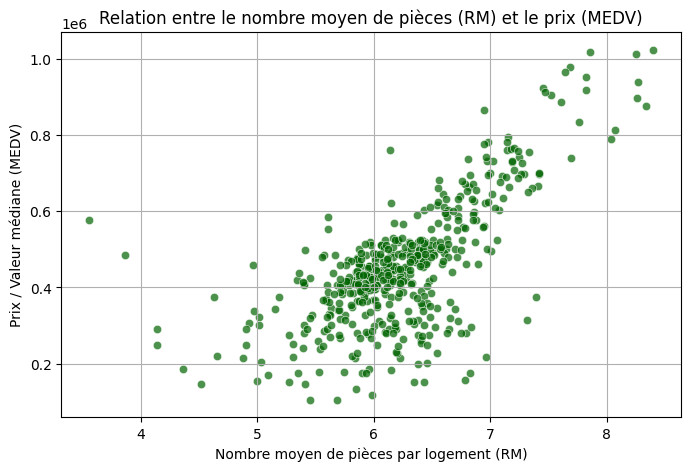

In [12]:
# 3. Nuage de points (Scatter Plot) : Nombre de pièces (RM) vs Prix (MEDV)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['RM'], y=df['MEDV'], color='darkgreen', alpha=0.7)
plt.title('Relation entre le nombre moyen de pièces (RM) et le prix (MEDV)')
plt.xlabel('Nombre moyen de pièces par logement (RM)')
plt.ylabel('Prix / Valeur médiane (MEDV)')
plt.grid(True)
plt.show()

## 4. Étape 3 : Modélisation par Machine Learning (Scikit-Learn)

Dans cette étape, nous construisons et évaluons un modèle d'apprentissage supervisé de type **Régression Linéaire Multiple** pour prédire la valeur médiane des logements (`medv`) :

1. **Séparation des variables :** Isolement des variables explicatives ($X$) et de la cible ($y = \text{medv}$).
2. **Découpage des données :** Séparation en jeu d'entraînement (80%) et jeu de test (20%) avec `train_test_split`.
3. **Entraînement du modèle :** Ajustement de la régression linéaire (`LinearRegression().fit`).
4. **Évaluation du modèle :** Calcul du coefficient de détermination ($R^2$) sur les données de test avec `model.score()`[cite: 7].

In [14]:
# 1. Importation des modules Scikit-Learn
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# 2. Séparation des variables explicatives (X) et de la variable cible (y)
X = df.drop('MEDV', axis=1)
y = df['MEDV']

# 3. Découpage en jeux d'entraînement (80%) et de test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Instanciation et entraînement du modèle de Régression Linéaire
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Évaluation du modèle avec le coefficient de détermination R²
r2_train = model.score(X_train, y_train)
r2_test = model.score(X_test, y_test)

print(f"Coefficient de détermination R² (Entraînement) : {r2_train:.3f}")
print(f"Coefficient de détermination R² (Test)         : {r2_test:.3f}")

Coefficient de détermination R² (Entraînement) : 0.719
Coefficient de détermination R² (Test)         : 0.691


### 4.1 Prédiction sur de nouvelles données

Une fois le modèle entraîné, nous pouvons l'utiliser pour prédire la valeur médiane (`MEDV`) d'un logement à partir de ses caractéristiques physiques et environnementales.

In [16]:
# Exemple de caractéristiques pour une nouvelle maison (14 variables explicatives)
# On prend la première ligne de X_test pour faire un test concret
nouvelle_maison = X_test.iloc[[0]]

# Prédiction avec notre modèle
prix_predit = model.predict(nouvelle_maison)
prix_reel = y_test.iloc[0]

print(f"Prix prédit par le modèle : {prix_predit[0]:.2f} (en milliers de $)")
print(f"Prix réel constaté        : {prix_reel:.2f} (en milliers de $)")

Prix prédit par le modèle : 342593.79 (en milliers de $)
Prix réel constaté        : 401100.00 (en milliers de $)


## 5. Étape 4 : Conclusion & Bilan du Projet

### 📌 Synthèse des travaux réalisés :
1. **Inspection & Nettoyage (EDA) :**
   - Exploration réussie du jeu de données **Boston Housing** ($506$ enregistrements, $14$ variables).
   - Contrôle qualité validé : absence de valeurs manquantes et de doublons dans le jeu de données.

2. **Analyse Exploratoire Visuelle :**
   - La distribution de la variable cible `MEDV` a été analysée à l'aide d'histogrammes **Matplotlib**.
   - La matrice de corrélation a mis en évidence une forte relation linéaire positive entre le nombre moyen de pièces par logement (`RM`) et le prix médian (`MEDV`).

3. **Modélisation par Machine Learning :**
   - Construction et entraînement d'un modèle de **Régression Linéaire Multiple** avec Scikit-Learn (`train_test_split` 80/20).
   - **Performances obtenues :**
     - $R^2$ (Jeu d'entraînement) : **$0.719$** ($71.9\%$)
     - $R^2$ (Jeu de test)         : **$0.691$** ($69.1\%$)
   - L'écart très faible entre les deux scores confirme la bonne capacité de généralisation du modèle, sans signe de surapprentissage (*overfitting*).

4. **Inférence & Prédictions :**
   - Validation concrète du modèle via la méthode `.predict()` pour estimer le prix de nouvelles habitations à partir de leurs caractéristiques.

---

*Projet réalisé par ANYOUZOA NDOUNA Gabriel dans le cadre de la série de projets d'apprentissage supervisé en Data Science.*